In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("data")
print(sorted(p.name for p in DATA_DIR.glob("*.csv")))

['DCOILBRENTEU.csv', 'DCOILWTICO.csv', 'DFII10.csv', 'DTWEXBGS.csv', 'GC_F_yahoo.csv', 'VIXCLS.csv']


In [3]:
brent = pd.read_csv(DATA_DIR / "DCOILBRENTEU.csv")
print(brent.head())
print(brent.dtypes)
print("Rows:", len(brent), "| Missing prices:", brent["DCOILBRENTEU"].isna().sum())

  observation_date  DCOILBRENTEU
0       2015-01-02         55.38
1       2015-01-05         51.08
2       2015-01-06         50.12
3       2015-01-07         49.06
4       2015-01-08         49.43
observation_date     object
DCOILBRENTEU        float64
dtype: object
Rows: 3086 | Missing prices: 82


In [4]:
SERIES = {
    "brent": ("DCOILBRENTEU.csv", "DCOILBRENTEU"),
    "wti":   ("DCOILWTICO.csv",   "DCOILWTICO"),
    "gold":  ("GC_F_yahoo.csv",   "Adj Close"),
    "usd":   ("DTWEXBGS.csv",     "DTWEXBGS"),
    "vix":   ("VIXCLS.csv",       "VIXCLS"),
    "ry10":  ("DFII10.csv",       "DFII10"),
}

columns = {}
for name, (file, col) in SERIES.items():
    df = pd.read_csv(DATA_DIR / file)
    date_col = df.columns[0]
    values = pd.to_numeric(df[col], errors="coerce")
    columns[name] = pd.Series(values.values, index=pd.to_datetime(df[date_col]))

raw = pd.concat(columns, axis=1).sort_index()
print(raw.head())
print(raw.tail())

            brent    wti  gold       usd    vix  ry10
2015-01-02  55.38  52.72   NaN  102.9027  17.79  0.41
2015-01-05  51.08  50.05   NaN  103.4976  19.92  0.40
2015-01-06  50.12  47.98   NaN  103.2938  21.12  0.41
2015-01-07  49.06  48.69   NaN  103.6316  19.31  0.39
2015-01-08  49.43    NaN   NaN  103.2799  17.01  0.41
             brent     wti  gold       usd    vix  ry10
2026-10-26  128.12  105.25   NaN  121.6042  18.39  2.66
2026-10-27  123.10  103.37   NaN  121.6622  17.52  2.64
2026-10-28  119.20  106.25   NaN  121.8491  16.91  2.67
2026-10-29  115.28  105.51   NaN  121.7361  17.20  2.63
2026-10-30  120.15  107.56   NaN  121.6656  19.42  2.60


In [5]:
raw = raw.loc["2021-10-01":"2026-09-30"]
print("Days in table:", len(raw))
print("First day:", raw.index[0].date(), "| Last day:", raw.index[-1].date())
print()
print("Missing values per series:")
print(raw.isna().sum())

Days in table: 1304
First day: 2021-10-01 | Last day: 2026-09-30

Missing values per series:
brent    41
wti      57
gold     47
usd      55
vix      17
ry10     56
dtype: int64


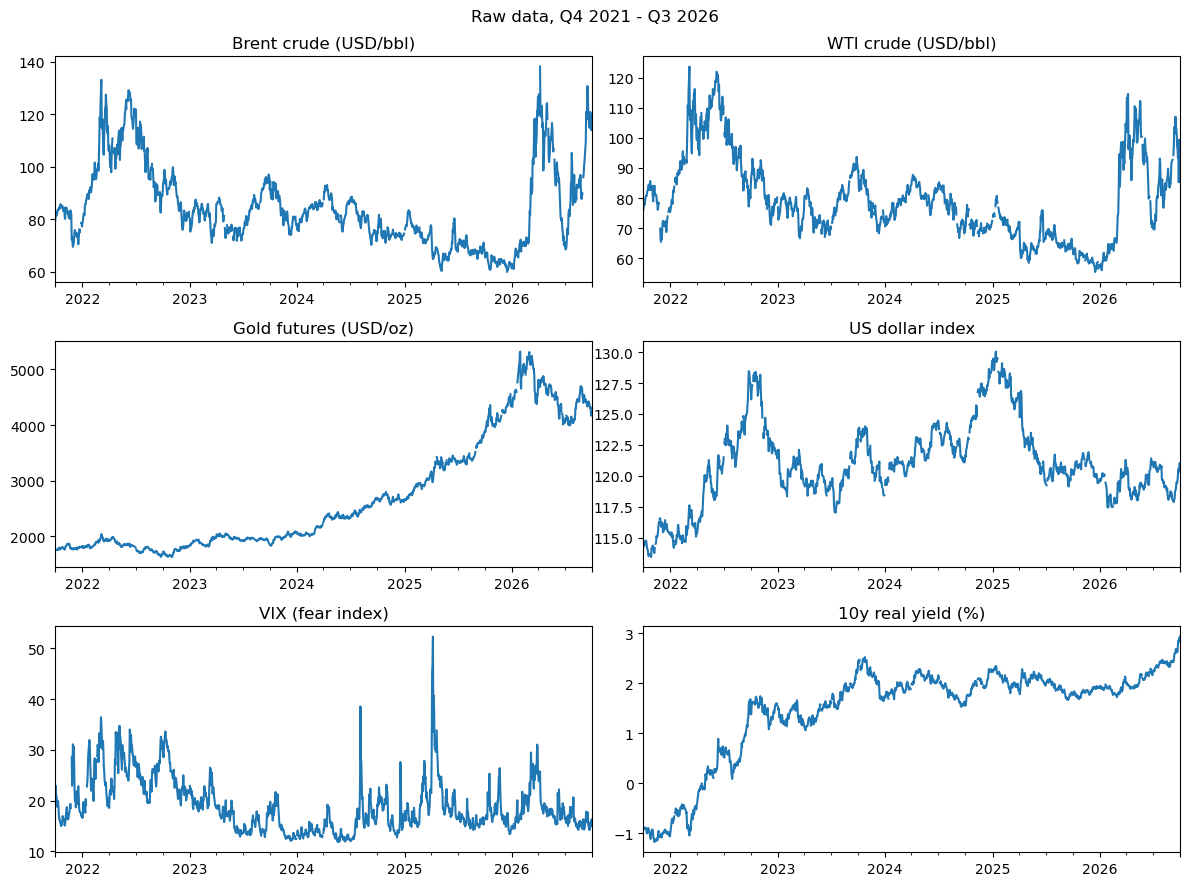

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9))
titles = {
    "brent": "Brent crude (USD/bbl)",
    "wti":   "WTI crude (USD/bbl)",
    "gold":  "Gold futures (USD/oz)",
    "usd":   "US dollar index",
    "vix":   "VIX (fear index)",
    "ry10":  "10y real yield (%)",
}
for ax, (name, title) in zip(axes.flat, titles.items()):
    raw[name].plot(ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")

plt.suptitle("Raw data, Q4 2021 - Q3 2026")
plt.tight_layout()
plt.show()

In [7]:
others = ["brent", "gold", "usd", "vix", "ry10"]

clean = raw.copy()
clean[others] = clean[others].ffill(limit=3)    # fill regressors only, max 3 days
clean = clean[clean["wti"].notna()]             # keep WTI trading days only
clean = clean.dropna()                          # drop anything still missing

print("Before:", len(raw), "days | After:", len(clean), "days")
print(clean.isna().sum())
print("Lowest WTI price:", clean["wti"].min())

Before: 1304 days | After: 1247 days
brent    0
wti      0
gold     0
usd      0
vix      0
ry10     0
dtype: int64
Lowest WTI price: 55.44


In [8]:
data = pd.DataFrame(index=clean.index)

data["y"]        = 100 * np.log(clean["wti"]).diff()      # WTI log return, %
data["usd_ret"]  = 100 * np.log(clean["usd"]).diff()      # dollar % change
data["vix_chg"]  = clean["vix"].diff()                    # VIX change, points
data["ry10_chg"] = 100 * clean["ry10"].diff()             # real yield change, bp
data["spread"]   = 100 * (np.log(clean["brent"]) - np.log(clean["wti"]))  # Brent premium over WTI, %
data["gold_ret"] = 100 * np.log(clean["gold"]).diff()     # gold log return, %

data = data.dropna()

print("Days:", len(data))
print(data.describe().round(3))
print(data.head(3).round(3))

Days: 1246
              y   usd_ret   vix_chg  ry10_chg    spread  gold_ret
count  1246.000  1246.000  1246.000  1246.000  1246.000  1246.000
mean      0.020     0.004    -0.004     0.307     6.048     0.070
std       2.659     0.322     1.742     5.683     3.324     1.213
min     -17.516    -1.320   -18.710   -27.000    -3.153   -11.406
25%      -1.352    -0.172    -0.758    -3.000     4.123    -0.500
50%       0.134     0.000    -0.120     0.000     5.732     0.084
75%       1.547     0.188     0.620     3.000     7.305     0.696
max      15.350     1.106    15.290    30.000    30.832     5.893
                y  usd_ret  vix_chg  ry10_chg  spread  gold_ret
2021-10-04  2.173   -0.093     1.81       1.0   4.727     0.522
2021-10-05  1.900    0.080    -1.66      -2.0   4.386    -0.380
2021-10-06 -1.926    0.308    -0.30       1.0   4.691     0.051


In [9]:
h = 1   # forecast horizon: 1 day ahead

regressors = ["y", "usd_ret", "vix_chg", "ry10_chg", "spread", "gold_ret"]

model_df = data[regressors].copy()
model_df.columns = [c + "_t" for c in regressors]   
model_df["target"] = data["y"].shift(-h)          
model_df = model_df.dropna()      
assert not (model_df["target"] == model_df["y_t"]).all(), "Target equals y_t: missing shift!"
assert model_df["target"].iloc[0] == model_df["y_t"].iloc[h], "Target is not the return h days ahead"             

print("Rows:", len(model_df))
print(model_df.head(3).round(3))


Rows: 1245
              y_t  usd_ret_t  vix_chg_t  ry10_chg_t  spread_t  gold_ret_t  \
2021-10-04  2.173     -0.093       1.81         1.0     4.727       0.522   
2021-10-05  1.900      0.080      -1.66        -2.0     4.386      -0.380   
2021-10-06 -1.926      0.308      -0.30         1.0     4.691       0.051   

            target  
2021-10-04   1.900  
2021-10-05  -1.926  
2021-10-06   1.025  


In [10]:
# Training vs Evaluation Split
eval_frac = 0.25                   

n = len(model_df)
split = int(round(n * (1 - eval_frac)))

train = model_df.iloc[:split]          
test  = model_df.iloc[split:]         

print("Total rows:", n)
print("Train:", len(train), "rows |", train.index[0].date(), "->", train.index[-1].date())
print("Test: ", len(test),  "rows |", test.index[0].date(),  "->", test.index[-1].date())

Total rows: 1245
Train: 934 rows | 2021-10-04 -> 2025-07-01
Test:  311 rows | 2025-07-02 -> 2026-09-29


In [11]:
X_train = train.drop(columns="target").to_numpy()           
X_train = np.column_stack([np.ones(len(X_train)), X_train]) 
y_train = train["target"].to_numpy()

beta, *_ = np.linalg.lstsq(X_train, y_train, rcond=None)    

names = ["const"] + list(train.columns.drop("target"))
print(pd.Series(beta, index=names).round(4))

errors = y_train - X_train @ beta
r2 = 1 - (errors @ errors) / ((y_train - y_train.mean()) ** 2).sum()
print("R-squared:", round(r2, 4))

const        -0.0457
y_t           0.0465
usd_ret_t     0.0025
vix_chg_t    -0.0310
ry10_chg_t    0.0036
spread_t      0.0063
gold_ret_t   -0.0380
dtype: float64
R-squared: 0.003


In [12]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [13]:
import statsmodels.api as sm

X_sm = sm.add_constant(train.drop(columns="target"))
y_sm = train["target"]

ols_fit = sm.OLS(y_sm, X_sm).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(ols_fit.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                 -0.003
Method:                 Least Squares   F-statistic:                    0.4811
Date:                Fri, 27 Nov 2026   Prob (F-statistic):              0.823
Time:                        22:32:16   Log-Likelihood:                -2134.1
No. Observations:                 934   AIC:                             4282.
Df Residuals:                     927   BIC:                             4316.
Df Model:                           6                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0457      0.182     -0.251      0.8

In [14]:
X_all = np.column_stack([np.ones(n), model_df.drop(columns="target").to_numpy()])
y_all = model_df["target"].to_numpy()

rows = []
for j in range(split, n):                 
    train_end = j - h + 1                 
    beta_j, *_ = np.linalg.lstsq(X_all[:train_end], y_all[:train_end], rcond=None)

    origin = model_df.index[j]
    target_date = data.index[data.index.get_loc(origin) + h]
    rows.append({
        "target_date": target_date,
        "origin": origin,
        "actual": y_all[j],
        "ols": X_all[j] @ beta_j,         # the forecast
        "naive": 0.0,                     # benchmark: "no change"
        "n_train": train_end,
    })

fc = pd.DataFrame(rows).set_index("target_date")
print("Forecasts:", len(fc))
print(fc.head(3).round({"actual": 3, "ols": 3}))
print(fc.tail(2).round({"actual": 3, "ols": 3}))

Forecasts: 311
                origin  actual    ols  naive  n_train
target_date                                          
2025-07-03  2025-07-02  -0.775  0.118    0.0      934
2025-07-07  2025-07-03   1.501 -0.028    0.0      935
2025-07-08  2025-07-07   0.562  0.016    0.0      936
                origin  actual    ols  naive  n_train
target_date                                          
2026-09-29  2026-09-28  -3.284  0.584    0.0     1243
2026-09-30  2026-09-29   1.055  0.291    0.0     1244


In [15]:
rmse = lambda col: np.sqrt(((fc["actual"] - fc[col]) ** 2).mean())
mae  = lambda col: (fc["actual"] - fc[col]).abs().mean()

print(f"OLS   RMSE = {rmse('ols'):.4f} | MAE = {mae('ols'):.4f}")
print(f"Naive RMSE = {rmse('naive'):.4f} | MAE = {mae('naive'):.4f}")
print(f"Loss ratio (OLS / naive): RMSE {rmse('ols')/rmse('naive'):.3f} | MAE {mae('ols')/mae('naive'):.3f}")

OLS   RMSE = 3.3865 | MAE = 2.2916
Naive RMSE = 3.3568 | MAE = 2.2772
Loss ratio (OLS / naive): RMSE 1.009 | MAE 1.006


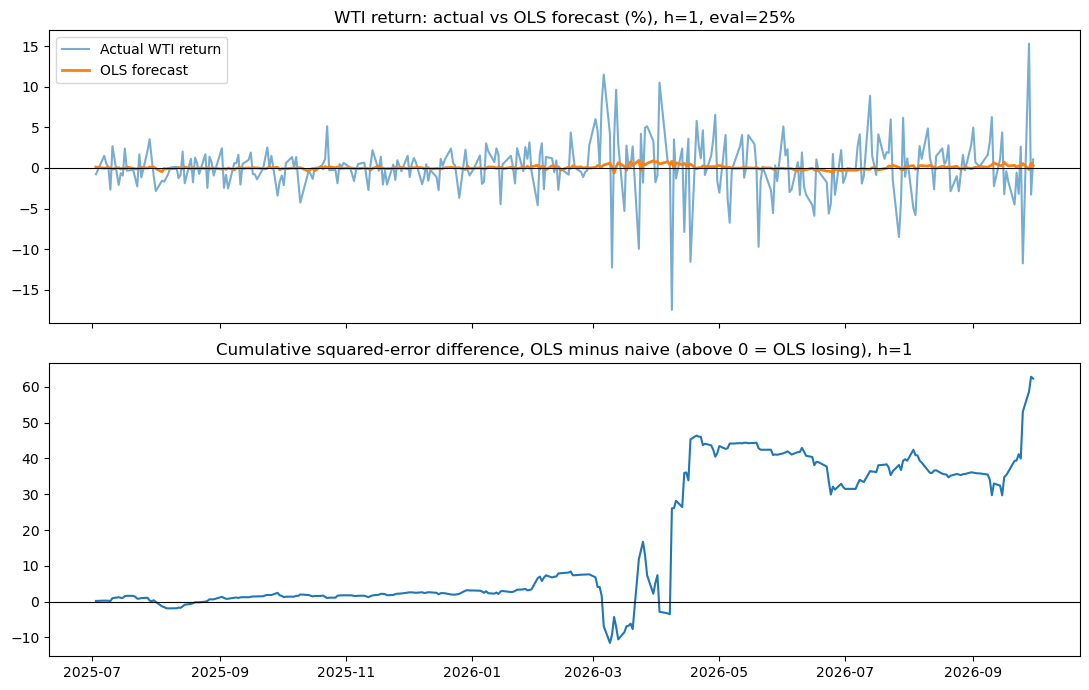

<Figure size 640x480 with 0 Axes>

In [16]:
# Visualization where OLS lose 
loss_diff = (fc["actual"] - fc["ols"])**2 - (fc["actual"] - fc["naive"])**2
cum = loss_diff.cumsum()

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(fc.index, fc["actual"], label="Actual WTI return", alpha=0.6)
axes[0].plot(fc.index, fc["ols"], label="OLS forecast", linewidth=2)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title(f"WTI return: actual vs OLS forecast (%), h={h}, eval={eval_frac:.0%}")
axes[0].legend()

axes[1].plot(cum.index, cum)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title(f"Cumulative squared-error difference, OLS minus naive (above 0 = OLS losing), h={h}")

plt.tight_layout()
plt.show()
plt.savefig(f"ols_forecast_h{h}.png", dpi=150)

In [17]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

resid = ols_fit.resid          # training-sample errors 

lb = acorr_ljungbox(resid, lags=[10])
arch_stat, arch_p, _, _ = het_arch(resid, nlags=5)

print(f"Ljung-Box Q(10):  stat = {lb['lb_stat'].iloc[0]:.2f}, p = {lb['lb_pvalue'].iloc[0]:.4f}")
print(f"ARCH-LM (5 lags): stat = {arch_stat:.2f}, p = {arch_p:.2e}")

Ljung-Box Q(10):  stat = 21.55, p = 0.0176
ARCH-LM (5 lags): stat = 71.11, p = 6.03e-14


In [18]:
from ols import load_data, forecast_ols, loss_ratios

data2 = load_data()
fc2 = forecast_ols(data2, h=1, eval_frac=0.25)
print(loss_ratios(fc2))

{'rmse_ols': np.float64(3.386471179006106), 'rmse_naive': np.float64(3.3567654522343315), 'mae_ols': np.float64(2.291600186907611), 'mae_naive': np.float64(2.277150290862341), 'rmse_ratio': np.float64(1.0088495092059535), 'mae_ratio': np.float64(1.0063456049006752)}


In [19]:
from statsmodels.tsa.stattools import adfuller

for col in data.columns:
    stat, p = adfuller(data[col].dropna())[:2]
    print(f"{col:10s} ADF = {stat:7.2f}   p = {p:.4f}")

y          ADF =  -14.42   p = 0.0000
usd_ret    ADF =  -34.54   p = 0.0000
vix_chg    ADF =  -16.10   p = 0.0000
ry10_chg   ADF =  -21.34   p = 0.0000
spread     ADF =   -4.07   p = 0.0011
gold_ret   ADF =  -26.49   p = 0.0000
